In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import RobustScaler

In [3]:
main_data = pd.read_csv(
    "data/Medicare_Physician_Other_Practitioners_by_Provider_and_Service_2024.csv",
    dtype={
        "Rndrng_NPI": "string",
        "HCPCS_Cd": "string",
        "Rndrng_Prvdr_State_FIPS": "string",
        "Rndrng_Prvdr_Zip5": "string",
    },
    low_memory=False,
)
main_data

,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
0,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,36,36.0,36,284.378889,79.063889,60.828889,62.376389
1,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with straightforward or ...,N,F,150,150.0,150,352.176333,126.340800,95.675600,96.007133
2,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Initial hospital care with moderate level of m...,N,F,63,63.0,63,783.997302,170.360000,134.300476,131.999365
3,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with straightforward ...,N,F,11,16.0,16,122.125000,47.832500,33.350625,33.706250
4,1003000126,Enkeshafi,Ardalan,NaN,M.D.,I,6410 Rockledge Dr Ste 304,NaN,Bethesda,MD,...,Subsequent hospital care with moderate levelof...,N,F,37,70.0,70,583.606857,81.428571,62.728714,58.486857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9781668,1992999825,Deschenes,Geoffrey,R,M.D.,I,1100 9th Ave,Ms:m4-Pfs,Seattle,WA,...,Established patient office or other outpatient...,N,O,80,92.0,92,330.000000,140.840326,104.658370,93.407065
9781669,1992999874,Joffe,Gabriella,NaN,NaN,I,5620 Brook Rd,NaN,Richmond,VA,...,Initial hospital care with moderate level of m...,N,F,36,36.0,36,780.583333,165.405000,131.781389,133.834444
9781670,1992999874,Joffe,Gabriella,NaN,NaN,I,5620 Brook Rd,NaN,Richmond,VA,...,Subsequent hospital care with moderate levelof...,N,F,188,329.0,329,278.127660,74.811337,59.662888,61.002462
9781671,1992999874,Joffe,Gabriella,NaN,NaN,I,5620 Brook Rd,NaN,Richmond,VA,...,Subsequent hospital care with moderate levelof...,N,F,99,153.0,153,398.522876,113.171438,89.568366,90.994967


In [6]:
col_group_1 = [
    "HCPCS_Cd",
    "Place_Of_Srvc",
    "Rndrng_Prvdr_Type",
    "Rndrng_Prvdr_Ent_Cd",
]

col_group_2 = [
    "Tot_Benes",
    "Tot_Bene_Day_Srvcs",
    "Tot_Srvcs",
    "Avg_Sbmtd_Chrg",
    "Avg_Mdcr_Alowd_Amt",
    "Avg_Mdcr_Stdzd_Amt",
]

Selected Peer Group: {'HCPCS_Cd': '99214', 'Place_Of_Srvc': 'O', 'Rndrng_Prvdr_Type': 'Nurse Practitioner', 'Rndrng_Prvdr_Ent_Cd': 'I'}
Rows: 91330
Excluded records: 0


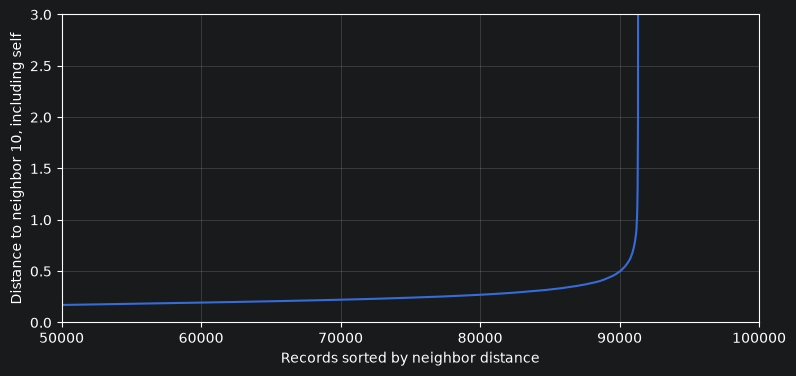

Clusters: 1
Noise percentage: 0.1%


,beneficiaries,services_per_beneficiary,services_per_beneficiary_day,charge_to_allowed,standardized_payment
cluster,,,,,
-1,24.0,1.82,1.0,4.241011,58.887118
0,54.0,1.30,1.0,2.457806,74.996368


cluster
-1      130
 0    91200
Name: count, dtype: int64

,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,HCPCS_Cd,Place_Of_Srvc,Tot_Benes,Tot_Bene_Day_Srvcs,Tot_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Stdzd_Amt,cluster
150167,1013434927,Walsh,99214,O,12,13,13.0,688.000000,90.729231,34.626923,-1
152299,1013451194,Weller,99214,O,15,16,16.0,624.000000,78.602500,37.179375,-1
233832,1023160330,Holder,99214,O,12,14,14.0,135.000000,102.245000,16.433571,-1
281787,1023579505,Gerardo,99214,O,474,1001,1001.0,1271.777323,109.781548,77.280250,-1
431959,1043375827,Naseri,99214,O,14,105,105.0,114.000000,100.330000,66.839429,-1
463452,1043645849,James,99214,O,18,18,18.0,455.000000,102.765556,25.803333,-1
595789,1063294502,Writch,99214,O,21,444,444.0,160.000000,101.106419,82.249730,-1
636732,1063583250,Campione,99214,O,49,788,788.0,265.000000,119.047018,81.897754,-1
666688,1063813178,Davidson,99214,O,21,107,107.0,125.000000,76.707009,54.807570,-1
687738,1073039863,Hill,99214,O,11,11,11.0,229.000000,111.854545,10.849091,-1


In [19]:
group_sizes = main_data.groupby(col_group_1, observed=True).size()
eligible = group_sizes[group_sizes.between(100,100000)]

selected_group = eligible.idxmax()

mask = pd.Series(True, index=main_data.index)
for column, value in zip(col_group_1, selected_group):
    mask &= main_data[column].eq(value)

subset = main_data.loc[mask].copy()

print('Selected Peer Group:', dict(zip(col_group_1, selected_group)))
print('Rows:', len(subset))

subset[col_group_2] = subset[col_group_2].apply(pd.to_numeric, errors='coerce')
subset[col_group_2] = subset[col_group_2].replace([np.inf, -np.inf], np.nan)

valid = (
    subset[col_group_2].notna().all(axis=1)
    & subset[col_group_2].ge(0).all(axis=1)
    & subset["Tot_Benes"].gt(0)
    & subset["Tot_Bene_Day_Srvcs"].gt(0)
    & subset["Avg_Mdcr_Alowd_Amt"].gt(0)
)

print("Excluded records:", int((~valid).sum()))
subset = subset.loc[valid].copy()

features = pd.DataFrame({
    "beneficiaries": subset["Tot_Benes"],
    "services_per_beneficiary": (
        subset["Tot_Srvcs"] / subset["Tot_Benes"]
    ),
    "services_per_beneficiary_day": (
        subset["Tot_Srvcs"] / subset["Tot_Bene_Day_Srvcs"]
    ),
    "charge_to_allowed": (
        subset["Avg_Sbmtd_Chrg"] / subset["Avg_Mdcr_Alowd_Amt"]
    ),
    "standardized_payment": subset["Avg_Mdcr_Stdzd_Amt"],
}, index=subset.index)

logged_features = np.log1p(features)

logged_features = logged_features.loc[
    :, logged_features.nunique() > 1
]

if logged_features.shape[1] == 0:
    raise ValueError("This group has no varying features.")

scaler = RobustScaler()
X = scaler.fit_transform(logged_features)

min_samples = 10

if len(X) < min_samples:
    raise ValueError("Too few valid records for this min_samples value.")

neighbors = NearestNeighbors(
    n_neighbors=min_samples,
    n_jobs=-1,
).fit(X)

distances, _ = neighbors.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(k_distances)
plt.ylim(0,3)
plt.xlim(50000,100000)
plt.xlabel("Records sorted by neighbor distance")
plt.ylabel(f"Distance to neighbor {min_samples}, including self")
plt.grid(alpha=0.3)
plt.show()

eps = 0.7

model = DBSCAN(
    eps=eps,
    min_samples=min_samples,
    metric="euclidean",
    n_jobs=-1,
)

subset["cluster"] = model.fit_predict(X)

n_clusters = subset.loc[
    subset["cluster"] != -1, "cluster"
].nunique()

print("Clusters:", n_clusters)
print(f"Noise percentage: {subset['cluster'].eq(-1).mean():.1%}")

summary = features.assign(cluster=subset["cluster"]).groupby(
    "cluster"
).median()

display(summary)
display(subset["cluster"].value_counts().sort_index())

review_cols = [
    "Rndrng_NPI",
    "Rndrng_Prvdr_Last_Org_Name",
    "HCPCS_Cd",
    "Place_Of_Srvc",
    *col_group_2,
    "cluster",
]

display(
    subset.loc[subset["cluster"].eq(-1), review_cols].head(30)
)

In [26]:
subset['neighbor_distance'] = distances[:, -1]
farthest = subset.sort_values(
    'neighbor_distance', ascending=False
)

temp = farthest[
        [
            "Rndrng_NPI",
            "Rndrng_Prvdr_Last_Org_Name",
            "HCPCS_Cd",
            "Place_Of_Srvc",
            "neighbor_distance",
            *col_group_2,
        ]
    ].head(30).drop(columns=['HCPCS_Cd', 'Place_Of_Srvc', 'Rndrng_NPI'])

display(
    temp
)

,Rndrng_Prvdr_Last_Org_Name,neighbor_distance,Tot_Benes,Tot_Bene_Day_Srvcs,Tot_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Stdzd_Amt
9349628,Perkins,8.190345,20,3846,3846.0,150.000000,79.638102,84.767101
5541016,Rochat,6.416076,12,12,12.0,207.000000,102.055833,2.820000
8505038,Ingraham,5.425615,29,30,30.0,244.000000,104.148000,3.470000
3332846,Apt,5.171565,16,1254,1254.0,131.560000,106.155375,84.384163
4298552,Callegari,4.423465,11,11,11.0,243.000000,102.850000,4.220000
2621640,Powell,3.562678,30,30,30.0,289.000000,78.990000,5.604000
2343486,Drown,3.240264,12,12,12.0,185.000000,107.720833,5.677500
1368064,Nowalk,3.194943,37,117,117.0,13.452991,13.185556,9.349744
2231949,Stratton,2.550102,11,11,11.0,188.000000,100.030000,6.980000
9658292,Johansen,2.384598,15,15,15.0,166.000000,105.227333,7.262000


,Rndrng_NPI,Rndrng_Prvdr_Last_Org_Name,Rndrng_Prvdr_First_Name,Rndrng_Prvdr_MI,Rndrng_Prvdr_Crdntls,Rndrng_Prvdr_Ent_Cd,Rndrng_Prvdr_St1,Rndrng_Prvdr_St2,Rndrng_Prvdr_City,Rndrng_Prvdr_State_Abrvtn,...,HCPCS_Desc,HCPCS_Drug_Ind,Place_Of_Srvc,Tot_Benes,Tot_Srvcs,Tot_Bene_Day_Srvcs,Avg_Sbmtd_Chrg,Avg_Mdcr_Alowd_Amt,Avg_Mdcr_Pymt_Amt,Avg_Mdcr_Stdzd_Amt
9349627,1952537649,Perkins,Deborah,L,"NP, PHD",I,2620 Regatta Dr Ste 246,NaN,Las Vegas,NV,...,Psychotherapy with evaluation and management v...,N,O,20,3826.0,3826,100.0,53.015721,42.018542,47.569634
9349628,1952537649,Perkins,Deborah,L,"NP, PHD",I,2620 Regatta Dr Ste 246,NaN,Las Vegas,NV,...,Established patient office or other outpatient...,N,O,20,3846.0,3846,150.0,79.638102,63.011986,84.767101
